In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout
import os
import numpy as np
from matplotlib import pyplot as plt
import cv2



In [2]:
# Load dataset
data = tf.keras.utils.image_dataset_from_directory('dataset/train', image_size=(256, 256))

# Normalize the data
data = data.map(lambda x, y: (x / 255.0, y))

# Split into training and validation datasets
train_size = int(len(data)*.8)
val_size = int(len(data)*.2)

train = data.take(train_size)
val = data.skip(train_size)

Found 9289 files belonging to 6 classes.


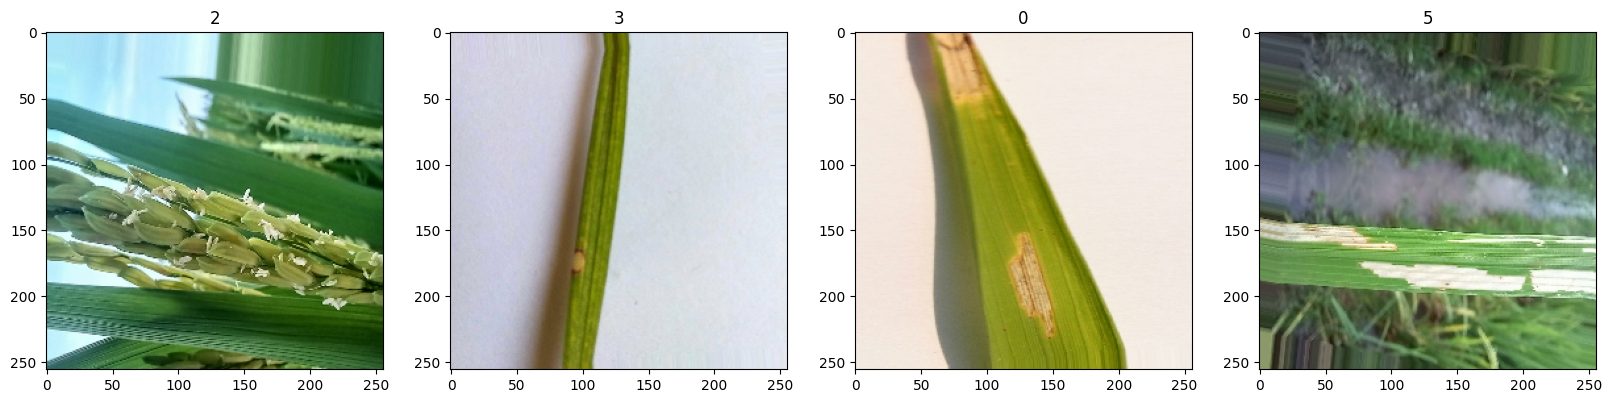

In [3]:
# Visualize a batch of data
data_iterator = train.as_numpy_iterator()
batch = data_iterator.next()

fig, ax = plt.subplots(ncols=4, figsize=(20, 20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img)
    ax[idx].title.set_text(batch[1][idx])


In [4]:
# Updated model architecture
model = Sequential([
    Conv2D(16, (3, 3), activation='relu', input_shape=(256, 256, 3)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3), 
    Dense(6, activation='softmax')  
])

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)
model.summary()


C:\Users\johnc\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,397,286 (28.22 MB)

 Trainable params: 7,397,286 (28.22 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Add early stopping to avoid overfitting
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    train,
    epochs=20,
    validation_data=val,
    callbacks=[early_stopping]
)


Epoch 1/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 1309s 6s/step - accuracy: 0.4032 - loss: 1.6309 - val_accuracy: 0.7437 - val_loss: 0.6884
Epoch 2/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 1183s 5s/step - accuracy: 0.7203 - loss: 0.7532 - val_accuracy: 0.7657 - val_loss: 0.6160
Epoch 3/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 1154s 5s/step - accuracy: 0.7932 - loss: 0.5537 - val_accuracy: 0.8113 - val_loss: 0.4863
Epoch 4/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 1309s 6s/step - accuracy: 0.8277 - loss: 0.4505 - val_accuracy: 0.8220 - val_loss: 0.4764
Epoch 5/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 1505s 6s/step - accuracy: 0.8626 - loss: 0.3504 - val_accuracy: 0.8488 - val_loss: 0.4150
Epoch 6/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 1348s 6s/step - accuracy: 0.8959 - loss: 0.2794 - val_accuracy: 0.8504 - val_loss: 0.4188
Epoch 7/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 1133s 5s/step - accuracy: 0.9159 - loss: 0.2245 - val_accuracy: 0.8772 - val_loss: 0.3975
Epoch 8/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 1129s 5s/step - accuracy: 0.9454 - loss: 0.1575 - 

In [6]:
# Evaluate the model
loss, accuracy = model.evaluate(val)
print(f"Validation Loss: {loss}")
print(f"Validation Accuracy: {accuracy}")

59/59 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.9172 - loss: 0.3016
Validation Loss: 0.3954223692417145
Validation Accuracy: 0.890080451965332


In [7]:
# Classification Report
from sklearn.metrics import classification_report

# Initialize true and predicted labels
y_true = [] 
y_pred = [] 

# Iterate over the validation dataset
for images, labels in val:
    predictions = model.predict(images) 
    y_true.extend(labels.numpy()) 
    y_pred.extend(np.argmax(predictions, axis=1))  


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 906ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 984ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 955ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 984ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 970ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 969ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 953ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 908ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 940ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 969ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━

In [8]:
# Define the class names (replace these with your actual classes)
class_names = ["bacterial_leaf_blight", "brown_spot", "healthy", "leaf_blast", "leaf_scald", "rice_hispa"]

# Print the classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Save the model
model.save('rice_leaf_disease_detection_model.h5')


Classification Report:
                       precision    recall  f1-score   support

bacterial_leaf_blight       0.98      0.99      0.98       289
           brown_spot       0.82      0.87      0.84       291
              healthy       0.86      0.84      0.85       310
           leaf_blast       0.84      0.76      0.80       344
           leaf_scald       0.97      0.94      0.95       334
           rice_hispa       0.87      0.97      0.92       297

             accuracy                           0.89      1865
            macro avg       0.89      0.89      0.89      1865
         weighted avg       0.89      0.89      0.89      1865



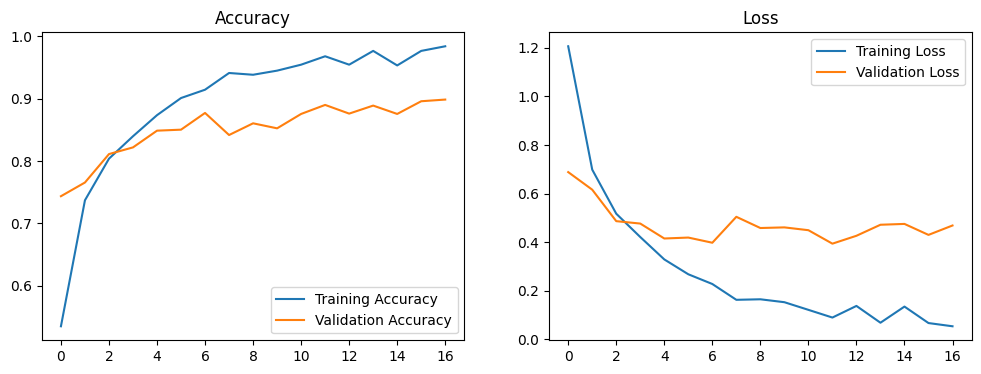

In [9]:
# Plot training and validation accuracy and loss
plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()


In [10]:
# Function to load and preprocess the image
def load_and_preprocess_image(image_path):
    
    img = cv2.imread(image_path)  # Load image
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img)  # Display original image
    plt.title("Original Image")
    plt.axis("off")
    plt.show()

    # Resize image to 256x256 and normalize pixel values
    img_resized = tf.image.resize(img, (256, 256))
    plt.imshow(img_resized.numpy().astype(int)) 
    plt.title("Resized Image")
    plt.axis("off")
    plt.show()

    # Normalize pixel values to [0, 1]
    img_normalized = img_resized / 255.0
    return img_normalized


In [11]:
def predict_image(image_path, model, classes):
    
    img = load_and_preprocess_image(image_path)  
    img_expanded = np.expand_dims(img, axis=0)  


    yhat = model.predict(img_expanded)
    predicted_class_idx = np.argmax(yhat, axis=-1)[0]  
    predicted_class = classes[predicted_class_idx]  
    confidence = yhat[0][predicted_class_idx] 

    print(f"Predicted Class: {predicted_class}")
    print(f"Confidence Score: {confidence:.2f}")

In [25]:
image_path = 'dataset/test/healthy/healthy (17).jpg'

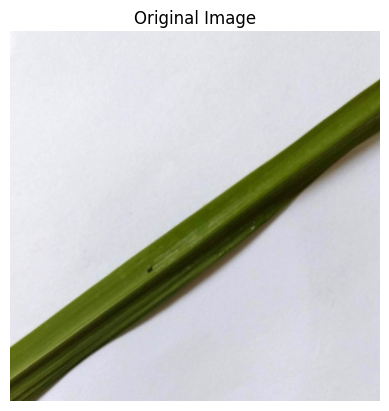

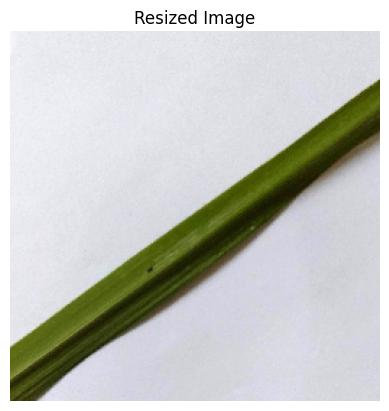

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 775ms/step
Predicted Class: healthy
Confidence Score: 0.99


In [26]:
# Load your trained model
model = tf.keras.models.load_model('Rice Leaf Disease Detection v2.h5')

# Predict and display results
predict_image(image_path, model, class_names)